# Practice Notebook 3: Hypothesis Tests, Effect Sizes, Errors, and Power

This practice notebook has two parts:

1. **Paper and pencil:** short questions that apply the lecture definitions and formulas.
2. **Python and interpretation:** three questions using brain-science examples.

For Part 1, write the reasoning as well as the final answer. For Part 2, run each cell and answer the interpretation questions before changing the code.

## Learning goals

By the end of the session, you should be able to:

- carry out the five steps of a hypothesis test
- compute one- and two-sample $t$ statistics and one- and two-proportion $z$ statistics
- interpret p-values and avoid common misinterpretations
- report effect sizes (mean difference, Cohen's d, odds ratio) alongside test results
- reason about Type I error, Type II error, and power when planning a study


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(2026)


# Part 1: Paper-and-pencil questions

Complete these questions without Python. You can use the calculator.


## 1. One-sample t-test, step by step

P300 latency in young adults averages 300 ms. In a sample of $n=16$ older adults, $\bar x=318$ ms and $s=40$ ms.

1. State $H_0$ and $H_1$ for a two-sided test.
2. Which assumptions should be checked?
3. Calculate $SE$, the test statistic, and its degrees of freedom.
4. With $t_{0.975,15}=2.131$, what is the decision at $\alpha=0.05$? Given $P(T_{15}\ge1.80)=0.046$, what is the two-sided p-value?
5. Calculate the 95% confidence interval. Is it consistent with the decision?
6. Suppose the directional hypothesis "older adults have longer latencies" had been specified before data collection, and a one-sided test is used ($t_{0.95,15}=1.753$). What changes? Why must the direction be fixed before seeing the data?
7. In the test statistic, which part reflects systematic variation and which reflects unsystematic variation?


### Solution

1. $$H_0:\mu=300\text{ ms},\qquad H_1:\mu\neq300\text{ ms}.$$

2. A random sample, independent observations, and a normal population or sufficiently large $n$. With $n=16$, check a histogram or boxplot for strong skew or outliers.

3. $$SE=\frac{40}{\sqrt{16}}=10\text{ ms},\qquad t=\frac{318-300}{10}=1.80,\qquad df=16-1=15.$$

4. $|t|=1.80<2.131$, so do not reject $H_0$. The two-sided p-value is $2(0.046)=0.092>0.05$.

5. $$318\pm2.131(10)=[296.7,\ 339.3]\text{ ms}.$$

The interval contains 300, which agrees with not rejecting $H_0$.

6. Now $H_1:\mu>300$. Because $t=1.80>1.753$ (one-sided $p=0.046<0.05$), $H_0$ is rejected. The direction must be fixed in advance: choosing the tail after seeing the data effectively tests in both directions, so the real Type I error rate becomes about 10% instead of 5%.

7. The numerator $\bar x-\mu_0=18$ ms is the systematic part (the deviation the hypothesis is about). The SE in the denominator reflects unsystematic variation (sampling noise). The statistic expresses the effect in SE units.


## 2. Two-sample (Welch) t-test and Cohen's d

Regional gray-matter volume (arbitrary units):

| Group | $n$ | $\bar x$ | $s$ |
|---|---|---|---|
| Controls | 20 | 52 | 6 |
| Patients | 25 | 47 | 8 |

1. State $H_0$ and $H_1$ for a two-sided comparison.
2. Why is a two-sample test appropriate, and why Welch's version rather than the pooled-variance version?
3. Calculate $SE$ and $t$ for $\bar x_C-\bar x_P$.
4. The Welch degrees of freedom are about 42.85 and $t_{0.975,42.85}\approx2.017$. What is the decision at $\alpha=0.05$?
5. Calculate the 95% confidence interval for $\mu_C-\mu_P$.
6. Calculate Cohen's d using the pooled SD $s_p=\sqrt{\frac{(n_1-1)s_1^2+(n_2-1)s_2^2}{n_1+n_2-2}}$ and interpret it.


### Solution

1. $$H_0:\mu_C-\mu_P=0,\qquad H_1:\mu_C-\mu_P\neq0.$$

2. The groups contain different people, so the samples are independent. The SDs differ (6 vs. 8) and the group sizes are unequal, so the equal-variance assumption of the pooled test is doubtful. Welch's test does not need it.

3. $$SE=\sqrt{\frac{6^2}{20}+\frac{8^2}{25}}=\sqrt{1.80+2.56}=\sqrt{4.36}\approx2.088,\qquad t=\frac{52-47}{2.088}\approx2.39.$$

4. $2.39>2.017$, so reject $H_0$ ($p\approx0.021$).

5. $$5\pm2.017(2.088)=5\pm4.21=[0.79,\ 9.21].$$

The interval excludes 0, which agrees with rejection. It is wide, so the size of the difference is imprecisely estimated.

6. $$s_p=\sqrt{\frac{19(36)+24(64)}{43}}=\sqrt{\frac{2220}{43}}\approx7.19,\qquad d=\frac{5}{7.19}\approx0.70.$$

The groups differ by about 0.7 standard deviations, a medium-to-large effect by Cohen's conventional benchmarks (0.2 small, 0.5 medium, 0.8 large).


## 3. One-proportion z-test

A patient with blindsight guesses the location of stimuli in a two-alternative task and is correct on 64 of 100 trials. Chance performance is 0.5.

1. State $H_0$ and $H_1$ (two-sided).
2. Check the validity conditions.
3. Calculate the z statistic.
4. Given $P(Z\ge2.8)\approx0.0026$, calculate the two-sided p-value and state the decision at $\alpha=0.05$.
5. Report the effect in an interpretable unit. What does the test **not** show?


### Solution

1. $$H_0:p=0.5,\qquad H_1:p\neq0.5.$$

2. $np_0=100(0.5)=50\ge10$ and $n(1-p_0)=50\ge10$, so the normal approximation is valid.

3. The SE uses $p_0$ (the value under $H_0$):

$$
z=\frac{0.64-0.5}{\sqrt{0.5(0.5)/100}}=\frac{0.14}{0.05}=2.8.
$$

4. $p=2(0.0026)\approx0.0051<0.05$, so reject $H_0$: performance is above chance.

5. Accuracy is 14 percentage points above chance. The test does not show conscious awareness, and the p-value alone does not tell us how large or clinically important the effect is.


## 4. Two-proportion z-test and the odds ratio

In a trial, 30 of 60 patients respond to a drug and 18 of 60 respond to placebo.

1. Calculate $\hat p_1$, $\hat p_2$, and the pooled proportion $\hat p$.
2. Calculate the SE and the z statistic.
3. Given $P(Z\ge2.236)\approx0.0127$, calculate the two-sided p-value and state the decision.
4. Calculate the odds ratio (drug vs. placebo) and interpret it.
5. Express the effect as a difference in percentage points.


### Solution

1. $$\hat p_1=\frac{30}{60}=0.50,\qquad \hat p_2=\frac{18}{60}=0.30,\qquad \hat p=\frac{30+18}{60+60}=0.40.$$

2. $$SE=\sqrt{0.40(0.60)\left(\frac{1}{60}+\frac{1}{60}\right)}=\sqrt{0.008}\approx0.0894,\qquad z=\frac{0.50-0.30}{0.0894}\approx2.24.$$

3. $p=2(0.0127)\approx0.025<0.05$, so reject $H_0:p_1-p_2=0$.

4. $$OR=\frac{0.50/0.50}{0.30/0.70}=\frac{1}{0.429}\approx2.33.$$

The odds of responding are about 2.3 times higher with the drug than with placebo.

5. The response rate is 20 percentage points higher (50% vs. 30%).


## 5. Interpreting p-values

A memory-training study reports $t(38)=2.20$, $p=0.034$ for training vs. control. Decide whether each statement is correct, and explain.

1. The probability that $H_0$ is true is 0.034.
2. If $H_0$ were true, a result at least as extreme as $|t|=2.20$ would occur in about 3.4% of such studies.
3. Because $p$ is small, the training effect is large and important.
4. A second study finds $p=0.21$. This proves that training has no effect.
5. At $\alpha=0.01$, the conclusion of the first study would be different.


### Solution

1. **Incorrect.** The p-value is computed **assuming** $H_0$ is true. It is not the probability of $H_0$.
2. **Correct.** This is the definition of a two-sided p-value: $P(|T|\ge|t_{obs}|\mid H_0)$.
3. **Incorrect.** The p-value does not measure effect size or importance. Report the mean difference or Cohen's d with a confidence interval.
4. **Incorrect.** Not rejecting $H_0$ is not evidence that $H_0$ is true. The study may have missed a real effect (Type II error), for example because of low power. A wide confidence interval would show this.
5. **Correct.** $0.034>0.01$, so $H_0$ would not be rejected.


## 6. Errors and power when planning a study

A lab plans a two-group study on whether neurofeedback training improves attention accuracy.

1. Describe a Type I error and a Type II error in this study.
2. Consider four designs:

| Design | $n$ per group | $\alpha$ | True effect $d$ |
|---|---|---|---|
| A | 20 | 0.05 | 0.5 |
| B | 80 | 0.05 | 0.5 |
| C | 80 | 0.01 | 0.5 |
| D | 80 | 0.05 | 0.2 |

Without calculating, decide whether B has more or less power than A, than C, and than D. Explain each comparison. (Part 2, Q2 lets you check the remaining comparisons.)

3. If $\beta=0.30$, what is the power, and what does it mean?
4. Name three ways to increase power without raising $\alpha$.
5. A study with 20,000 participants per group finds that reaction times differ by 1.5 ms (SD 50 ms), $p=0.002$. Calculate Cohen's d and comment.


### Solution

1. **Type I error:** concluding that neurofeedback improves attention when it has no effect in the population (false positive). **Type II error:** failing to detect a real improvement (false negative).

2. - **B vs. A:** B has more power. A larger sample gives a smaller SE, so the same effect is easier to distinguish from noise.
   - **B vs. C:** B has more power. The stricter $\alpha=0.01$ in C demands stronger evidence, which reduces power when $n$ and the effect are fixed.
   - **B vs. D:** B has more power. A smaller true effect ($d=0.2$) is harder to detect.

3. Power $=1-\beta=0.70$. If the specified true effect exists, the study rejects $H_0$ in about 70% of repetitions and misses it in about 30%.

4. Increase $n$; increase the true effect (a stronger or longer manipulation); reduce unexplained variability (more reliable measures, more trials per participant, a within-subject design).

5. $$d=\frac{1.5}{50}=0.03.$$

The result is statistically significant but negligible in size. With huge samples, the SE is tiny, so trivial differences become significant. Statistical significance is not the same as scientific importance; report the effect size and confidence interval.


# Part 2: Python and interpretation

The code is complete and runnable. Your task is to inspect the output, connect it to the lecture, and make small changes when requested.


## Q1: Running tests in Python and checking them by hand

We test a new sample of $n=12$ older adults against the young-adult P300 latency of 300 ms, first by hand and then with SciPy. We also revisit the blindsight data from Part 1, Question 3, comparing the normal approximation with an exact binomial test.


In [2]:
latencies = np.array([312, 335, 298, 341, 307, 326, 319, 352, 301, 330, 315, 344])
mu_0 = 300

n = len(latencies)
xbar = latencies.mean()
s = latencies.std(ddof=1)
se = s / np.sqrt(n)
t_manual = (xbar - mu_0) / se
t_crit = stats.t.ppf(0.975, df=n - 1)
ci = (xbar - t_crit * se, xbar + t_crit * se)

two_sided = stats.ttest_1samp(latencies, mu_0)
one_sided = stats.ttest_1samp(latencies, mu_0, alternative="greater")

print(f"Mean = {xbar:.2f} ms, SD = {s:.2f} ms, SE = {se:.2f} ms")
print(f"Manual t({n - 1}) = {t_manual:.3f}; SciPy t = {two_sided.statistic:.3f}")
print(f"Two-sided p = {two_sided.pvalue:.5f}; one-sided p = {one_sided.pvalue:.5f}")
print(f"95% CI = [{ci[0]:.2f}, {ci[1]:.2f}] ms")

# Blindsight: 64 correct out of 100, chance = 0.5
correct, trials, p_0 = 64, 100, 0.5
z = (correct / trials - p_0) / np.sqrt(p_0 * (1 - p_0) / trials)
p_z = 2 * stats.norm.sf(abs(z))
p_exact = stats.binomtest(correct, trials, p_0).pvalue
print(f"\nBlindsight: z = {z:.2f}, normal-approximation p = {p_z:.4f}, exact binomial p = {p_exact:.4f}")


Mean = 323.33 ms, SD = 17.51 ms, SE = 5.05 ms
Manual t(11) = 4.616; SciPy t = 4.616
Two-sided p = 0.00075; one-sided p = 0.00037
95% CI = [312.21, 334.46] ms

Blindsight: z = 2.80, normal-approximation p = 0.0051, exact binomial p = 0.0066


### Interpretation questions

1. Do the manual and SciPy test statistics agree?
2. What is the decision at $\alpha=0.05$? Part 1, Question 1 had a larger sample but did not reject $H_0$. Why does this smaller sample give a clear result?
3. How are the one-sided and two-sided p-values related?
4. Does the 95% confidence interval agree with the test decision?
5. Compare the normal-approximation p-value with the exact binomial p-value for the blindsight data. Why are they close?


### Model interpretation

1. Yes. Both give $t(11)\approx4.62$. SciPy's `ttest_1samp` uses exactly $(\bar x-\mu_0)/(s/\sqrt n)$ with $df=n-1$.

2. $p\approx0.0007<0.05$, so reject $H_0$: mean latency (about 323 ms) is longer than 300 ms. In Part 1, $s=40$ ms gave $SE=10$ ms. Here $s\approx17.5$ ms gives $SE\approx5.1$ ms, and the deviation is larger (23 vs. 18 ms). Less unexplained variability can outweigh a smaller $n$.

3. The one-sided p-value (about 0.0004) is half the two-sided p-value, because the effect lies in the predicted direction and only one tail is counted.

4. Yes. The interval of about $[312.2,\ 334.5]$ ms excludes 300, which matches rejection at $\alpha=0.05$.

5. The approximation gives $p\approx0.0051$ and the exact binomial test $p\approx0.0066$. Both lead to rejection. They are close because $np_0=n(1-p_0)=50\ge10$, so the CLT makes the normal approximation accurate.


## Q2: Power curves

We estimate the power of Welch's two-sample t-test by simulation. For each true effect size $d$ (in SD units) and sample size per group, we simulate 4,000 studies and record the proportion that reject $H_0$ at $\alpha=0.05$. We also estimate power for designs A–D from Part 1, Question 6.


    d    n=10    n=20    n=40    n=64   n=100   n=160
  0.0   0.043   0.054   0.049   0.046   0.052   0.051
  0.2   0.076   0.089   0.139   0.201   0.302   0.451
  0.5   0.176   0.337   0.609   0.814   0.944   0.994
  0.8   0.394   0.695   0.947   0.995   1.000   1.000

A: n=20, alpha=0.05, d=0.5: power = 0.327
B: n=80, alpha=0.05, d=0.5: power = 0.880
C: n=80, alpha=0.01, d=0.5: power = 0.705
D: n=80, alpha=0.05, d=0.2: power = 0.244


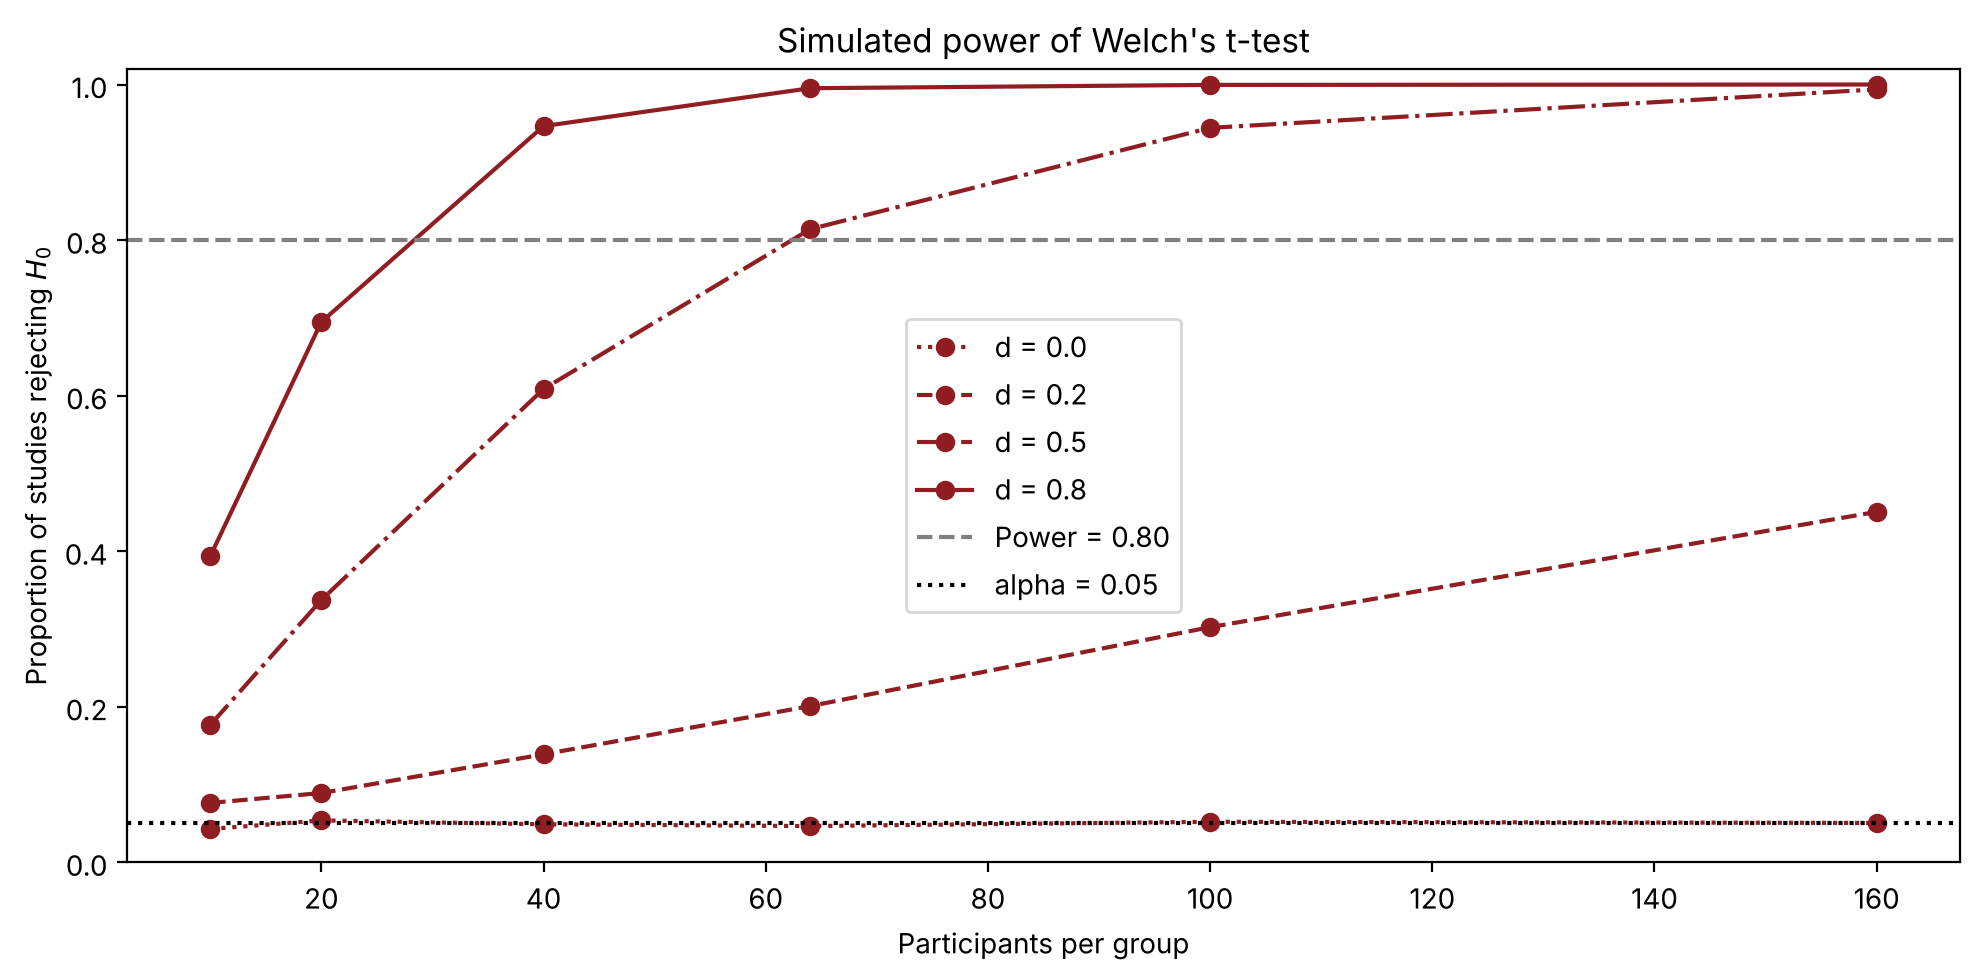

In [3]:
rng = np.random.default_rng(99)


def simulated_power(d, n, alpha=0.05, sims=4000):
    group_a = rng.normal(0, 1, size=(sims, n))
    group_b = rng.normal(d, 1, size=(sims, n))
    p_values = stats.ttest_ind(group_a, group_b, axis=1, equal_var=False).pvalue
    return np.mean(p_values < alpha)


sample_sizes = [10, 20, 40, 64, 100, 160]
effect_sizes = [0.0, 0.2, 0.5, 0.8]

power = {d: [simulated_power(d, n) for n in sample_sizes] for d in effect_sizes}

print(f"{'d':>5}" + "".join(f"{'n=' + str(n):>8}" for n in sample_sizes))
for d in effect_sizes:
    print(f"{d:5.1f}" + "".join(f"{p:8.3f}" for p in power[d]))

designs = {
    "A: n=20, alpha=0.05, d=0.5": simulated_power(0.5, 20),
    "B: n=80, alpha=0.05, d=0.5": simulated_power(0.5, 80),
    "C: n=80, alpha=0.01, d=0.5": simulated_power(0.5, 80, alpha=0.01),
    "D: n=80, alpha=0.05, d=0.2": simulated_power(0.2, 80),
}
print()
for name, value in designs.items():
    print(f"{name}: power = {value:.3f}")

fig, ax = plt.subplots(figsize=(10, 5))
for d, style in zip(effect_sizes, [":", "--", "-.", "-"]):
    ax.plot(sample_sizes, power[d], "o", linestyle=style, color="#8f1d21", label=f"d = {d}")
ax.axhline(0.80, color="grey", linestyle="--", label="Power = 0.80")
ax.axhline(0.05, color="black", linestyle=":", label="alpha = 0.05")
ax.set_xlabel("Participants per group")
ax.set_ylabel("Proportion of studies rejecting $H_0$")
ax.set_title("Simulated power of Welch's t-test")
ax.set_ylim(0, 1.02)
ax.legend()
plt.tight_layout()
plt.show()


### Interpretation questions

1. What does the row for $d=0$ estimate? Why does it stay close to 0.05 for every $n$?
2. For $d=0.5$, what is the smallest sample size in the table with power of at least 0.80?
3. What is the power for $d=0.2$ with 160 participants per group? What does this imply for studying small effects?
4. Use the design estimates to rank A–D by power. Does this agree with Part 1, Question 6?
5. Why does lowering $\alpha$ from 0.05 to 0.01 (B vs. C) reduce power?
6. What is the power for $d=0.8$ with only 10 participants per group? What does this imply for small studies?


### Model interpretation

1. With $d=0$, $H_0$ is true, so every rejection is a Type I error. The row estimates the Type I error rate, which is fixed by $\alpha$ and stays near 0.05 (0.043–0.054) regardless of $n$. Increasing $n$ raises power without raising $\alpha$.

2. About 64 participants per group (power ≈ 0.81). With 40 per group, power is only about 0.61.

3. About 0.45. Even with 160 per group, a study of a small effect misses it more often than it detects it. Small effects require several hundred participants per group.

4. B (≈ 0.88) > C (≈ 0.71) > A (≈ 0.33) > D (≈ 0.24). This agrees with the three comparisons in Part 1 and adds the ordering of C, A, and D, which depends on how much each factor changes.

5. A stricter $\alpha$ moves the critical value further into the tail. For the same true effect and $n$, fewer studies produce a statistic beyond it, so fewer reject $H_0$: fewer false positives, but more false negatives.

6. Only about 0.39, even for a large effect. Small studies frequently miss real effects, and a non-significant result from such a study says little.


## Q3: Statistical significance vs. effect size

We simulate two studies of reaction-time differences (SD = 50 ms in both groups):

- **Study A:** 20,000 participants per group, true difference 1.5 ms.
- **Study B:** 12 participants per group, true difference 25 ms ($d=0.5$).

For each, we report the mean difference, the 95% Welch confidence interval, the test result, and Cohen's d.


In [4]:
rng = np.random.default_rng(2028)


def summarize(control, treatment, label):
    diff = treatment.mean() - control.mean()
    result = stats.ttest_ind(treatment, control, equal_var=False)
    ci = result.confidence_interval(0.95)
    n1, n2 = len(control), len(treatment)
    s_pooled = np.sqrt(((n1 - 1) * control.var(ddof=1) + (n2 - 1) * treatment.var(ddof=1))
                       / (n1 + n2 - 2))
    print(f"{label}")
    print(f"  Mean difference = {diff:.2f} ms, 95% CI = [{ci.low:.2f}, {ci.high:.2f}] ms")
    print(f"  Welch t({result.df:.1f}) = {result.statistic:.2f}, p = {result.pvalue:.4f}")
    print(f"  Cohen's d = {diff / s_pooled:.3f}")


control_a = rng.normal(500, 50, size=20_000)
treatment_a = rng.normal(501.5, 50, size=20_000)
summarize(control_a, treatment_a, "Study A: n = 20,000 per group, true difference 1.5 ms")

control_b = rng.normal(500, 50, size=12)
treatment_b = rng.normal(525, 50, size=12)
summarize(control_b, treatment_b, "Study B: n = 12 per group, true difference 25 ms")


Study A: n = 20,000 per group, true difference 1.5 ms
  Mean difference = 1.53 ms, 95% CI = [0.55, 2.51] ms
  Welch t(39995.5) = 3.06, p = 0.0022
  Cohen's d = 0.031
Study B: n = 12 per group, true difference 25 ms
  Mean difference = 23.94 ms, 95% CI = [-11.18, 59.07] ms
  Welch t(18.5) = 1.43, p = 0.1696
  Cohen's d = 0.584


### Interpretation questions

1. Which study is statistically significant at $\alpha=0.05$? Which has the larger effect size?
2. Interpret the confidence interval of Study A. Is the effect practically important for reaction times?
3. Interpret the confidence interval of Study B. Does it show that the true difference is 0?
4. Which kind of error, if any, did Study B make? Why was it likely?
5. What should both studies report in addition to the p-value?


### Model interpretation

1. Study A is significant ($p\approx0.002$) and Study B is not ($p\approx0.17$). However, Study B has the much larger effect size ($d\approx0.58$ vs. $d\approx0.03$).

2. Study A estimates a difference of about 1.5 ms, 95% CI about $[0.55,\ 2.51]$ ms. The interval is very narrow (high precision) and excludes 0, but all plausible values are tiny compared with an SD of 50 ms. The effect is real but practically negligible.

3. Study B estimates about 24 ms, 95% CI about $[-11,\ 59]$ ms. The interval includes 0 but also large effects. The result is **inconclusive**, not evidence of no effect.

4. The true difference is 25 ms, so failing to reject $H_0$ is a **Type II error**. It was likely: with 12 participants per group and $d=0.5$, power is only about 0.21 (compare the power table in Q2), so most such studies miss the effect.

5. The effect estimate in the original units (and/or Cohen's d) together with its confidence interval, interpreted in context. Significance does not equal scientific importance, and non-significance does not equal no effect.
